# **실습 개요**

여러분은 한 IT 기업의 인사(HR) 데이터 분석팀에 합류한 데이터 분석가입니다. <br>
최근 우수 인재들의 퇴사(이직)가 이어지면서 경영진은 **어떤 직원이 이직할 가능성이 높은지**를 미리 예측하여 <br>선제적으로 리텐션(인재 유지) 프로그램을 운영하고자 합니다.

인사팀이 보유한 직원 데이터에는 입력 과정에서 발생한 결측치와 이상치, 그리고 중복 입력된 레코드가 섞여 있습니다.<br>
이 데이터를 정제하고, 여러 개의 결정 트리를 결합한 **랜덤 포레스트(Random Forest)** 앙상블 모델을 학습시켜 <br>
새로운 직원의 이직 여부를 예측해봅시다.

## **데이터셋 설명**

직원 개인 정보와 근무 만족도, 근태 관련 정보를 담고 있는 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| emp_id | 직원 고유 ID |
| age | 나이 |
| department | 소속 부서 (Sales / R&D / HR) |
| business_travel | 출장 빈도 (Non-Travel / Travel_Rarely / Travel_Frequently) |
| distance_from_home | 자택-회사 간 거리 (km) |
| education_level | 학력 수준 (1~5, 숫자가 클수록 높은 학력) |
| marital_status | 결혼 여부 (Single / Married / Divorced) |
| monthly_income | 월 급여 (달러) |
| num_companies_worked | 이전 이직 경험 횟수 |
| overtime | 야근 여부 (Yes / No) |
| total_working_years | 총 경력 연수 |
| years_at_company | 현재 회사 근속 연수 |
| job_satisfaction | 직무 만족도 (1~4, 클수록 만족) |
| environment_satisfaction | 근무 환경 만족도 (1~4, 클수록 만족) |
| work_life_balance | 워라밸 만족도 (1~4, 클수록 만족) |
| performance_rating | 최근 성과 평가 등급 (1~4, 클수록 우수) |
| attrition | **[target]** 이직 여부 (Yes = 이직, No = 잔류) |

## **데이터셋 URL**
https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/employee_attrition.csv


## **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

**Q1. 필요한 라이브러리를 불러오고, 데이터를 읽어온 뒤 첫 5개의 행을 출력하세요.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/employee_attrition.csv")
df.head()

,emp_id,age,department,business_travel,distance_from_home,education_level,marital_status,monthly_income,num_companies_worked,overtime,total_working_years,years_at_company,job_satisfaction,environment_satisfaction,work_life_balance,performance_rating,attrition
0,10524,52,HR,Travel_Frequently,3.6,2,Single,5730.0,3,No,25.6,16.7,4.0,3,3.0,3,No
1,10603,49,R&D,Travel_Rarely,33.7,2,Divorced,5970.0,6,No,27.1,5.7,3.0,3,4.0,4,No
2,10527,56,Sales,Travel_Rarely,11.4,3,Married,7560.0,6,No,35.5,20.4,1.0,2,2.0,3,No
3,10032,29,Sales,Travel_Rarely,8.0,4,Married,4050.0,3,Yes,7.9,6.3,4.0,2,1.0,4,No
4,10617,29,R&D,Travel_Rarely,7.8,2,Divorced,2940.0,7,Yes,5.8,1.3,1.0,3,NaN,3,Yes


**Q2. 데이터의 shape(행, 열 개수)을 확인하세요.**

In [3]:
# code here
df.shape

(1020, 17)

**Q3. 각 컬럼의 데이터 타입과 결측치 여부를 확인하세요.**

In [7]:
# code here

df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   emp_id                    1020 non-null   int64  
 1   age                       1020 non-null   int64  
 2   department                1020 non-null   str    
 3   business_travel           1020 non-null   str    
 4   distance_from_home        1020 non-null   float64
 5   education_level           1020 non-null   int64  
 6   marital_status            1020 non-null   str    
 7   monthly_income            969 non-null    float64
 8   num_companies_worked      1020 non-null   int64  
 9   overtime                  1020 non-null   str    
 10  total_working_years       1020 non-null   float64
 11  years_at_company          1020 non-null   float64
 12  job_satisfaction          990 non-null    float64
 13  environment_satisfaction  1020 non-null   int64  
 14  work_life_balance  

emp_id                       0
age                          0
department                   0
business_travel              0
distance_from_home           0
education_level              0
marital_status               0
monthly_income              51
num_companies_worked         0
overtime                     0
total_working_years          0
years_at_company             0
job_satisfaction            30
environment_satisfaction     0
work_life_balance           40
performance_rating           0
attrition                    0
dtype: int64

**Q4. 수치형 컬럼들의 통계 요약을 확인하세요.**

In [ ]:
# code here
df.describe()


## **2. 데이터 분석하기**

### **2-1. 데이터 탐색**

데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.


**colab에서 csv 파일 다운로드하기**
```
from google.colab import files
files.download("submission.csv")
```

**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 이직(attrition)별 비율을 소수점 2자리까지 찾아 주세요. (백분율)

In [38]:
# code here
(df["attrition"].value_counts(normalize=True) * 100).round(2)

attrition
No     73.53
Yes    26.47
Name: proportion, dtype: float64

**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 이직을 결정한 사원들 중, 야근을 한 비율을 소수점 2자리까지 찾아 주세요. (백분율)

In [59]:
# code here
ya  = (df[df["attrition"] == "Yes"]["overtime"].value_counts(normalize=True) * 100).round(2)
ya["Yes"]

np.float64(43.33)

In [72]:
df.groupby("overtime")["attrition"].apply(
    lambda x: (x == 'Yes').mean() * 100
).round(2)

overtime
No     21.46
Yes    38.11
Name: attrition, dtype: float64

**Q3. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 이직(attrition) 결정 별 월급의 평균을 소수점 2자리까지 찾아 주세요.

In [18]:
# code here
df.groupby("attrition")["monthly_income"].mean().round(2)

attrition
No     5211.29
Yes    3639.43
Name: monthly_income, dtype: float64

**Q4. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 근속연수가 가장 많은 10명의 평균 연봉을 소수점 2자리까지 찾아 주세요.
- 이직 경험 (num_companies worked)이 4회 이상인 직원들의 이직률 (attrition==yes)의 평균을 소수점 2자리까지 찾아 주세요. (백분율)
- 이직을 선택한 그룹의 최저만족도(job_satisfaction==1)인 직원들의 비율을 소수점 2자리까지 찾아 주세요.(백분율)

그리고 "ans" 컬럼에 정답을 순서대로 저장하여 제출합니다.

In [37]:
ans = []

In [36]:
# code here
df.sort_values("years_at_company", ascending=False).head(10)["monthly_income"].mean().round(2)


np.float64(7974.0)

In [58]:
df_new = df[df["num_companies_worked"] >= 4]
s = (df_new["attrition"].value_counts(normalize=True) * 100).round(2)
s["Yes"]

np.float64(30.98)

In [51]:
df_attr = df[df["attrition"] == "Yes"]
df_attr["job_satisfaction"].value_counts(normalize=True)

job_satisfaction
1.0    0.396154
2.0    0.253846
3.0    0.184615
4.0    0.165385
Name: proportion, dtype: float64

### **2-2. 데이터 시각화**

**Q1. attrition의 분포를 countplot으로 시각화하세요.**

그리고 해당 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

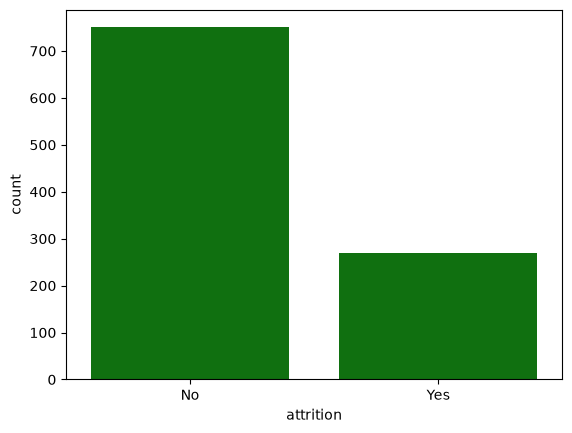

In [63]:
# code here
sns.countplot(df, x = "attrition", color = "g")
plt.show()

**Q2. 이직 여부에 따른 monthly_income의 분포를 히스토그램으로 겹쳐서 시각화하세요.**

그리고 해당 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

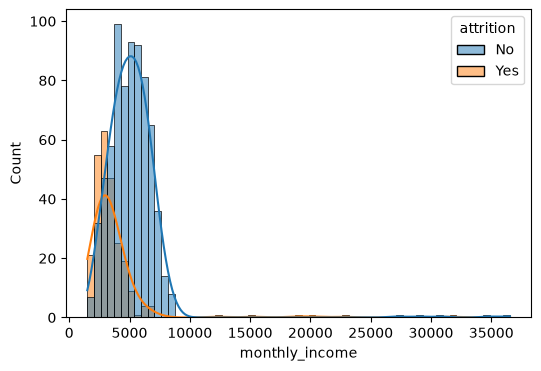

In [80]:
# code here
plt.figure(figsize=(6,4))
sns.histplot(df, x = "monthly_income", hue = "attrition", kde = True)
plt.show()

**Q3. 야근 여부별 이직률을 막대그래프로 시각화하세요.**

그리고 해당 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

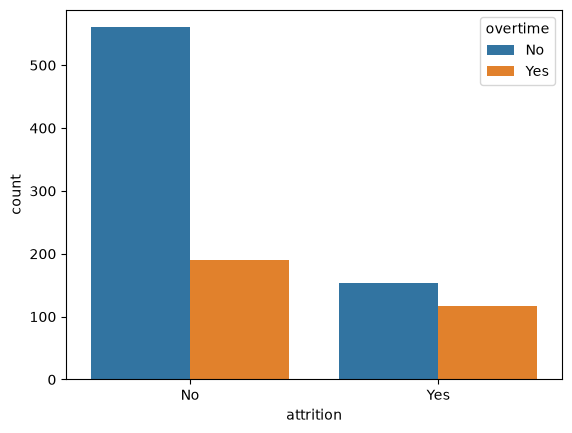

In [76]:
# code here
sns.countplot(df, x = "attrition", hue = "overtime")
plt.show()

**Q5. 나이와 월급의 관계를 이직 여부로 색상을 구분하여 산점도로 시각화하세요.**

그리고 해당 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

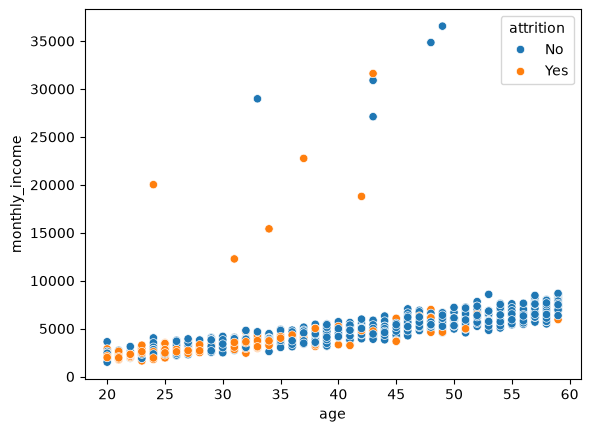

In [ ]:
# code here

sns.scatterplot(df, x = "age", y = "monthly_income", hue = "attrition")
plt.show()

**Q6. 회사까지의 거리와 이직률율을 막대 그래프로 시각화하세요.**

그리고 해당 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

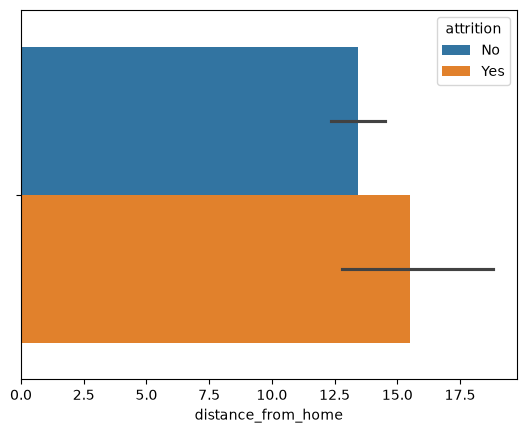

In [91]:
# code here
sns.barplot(df, x = "distance_from_home", hue = "attrition")
plt.show()

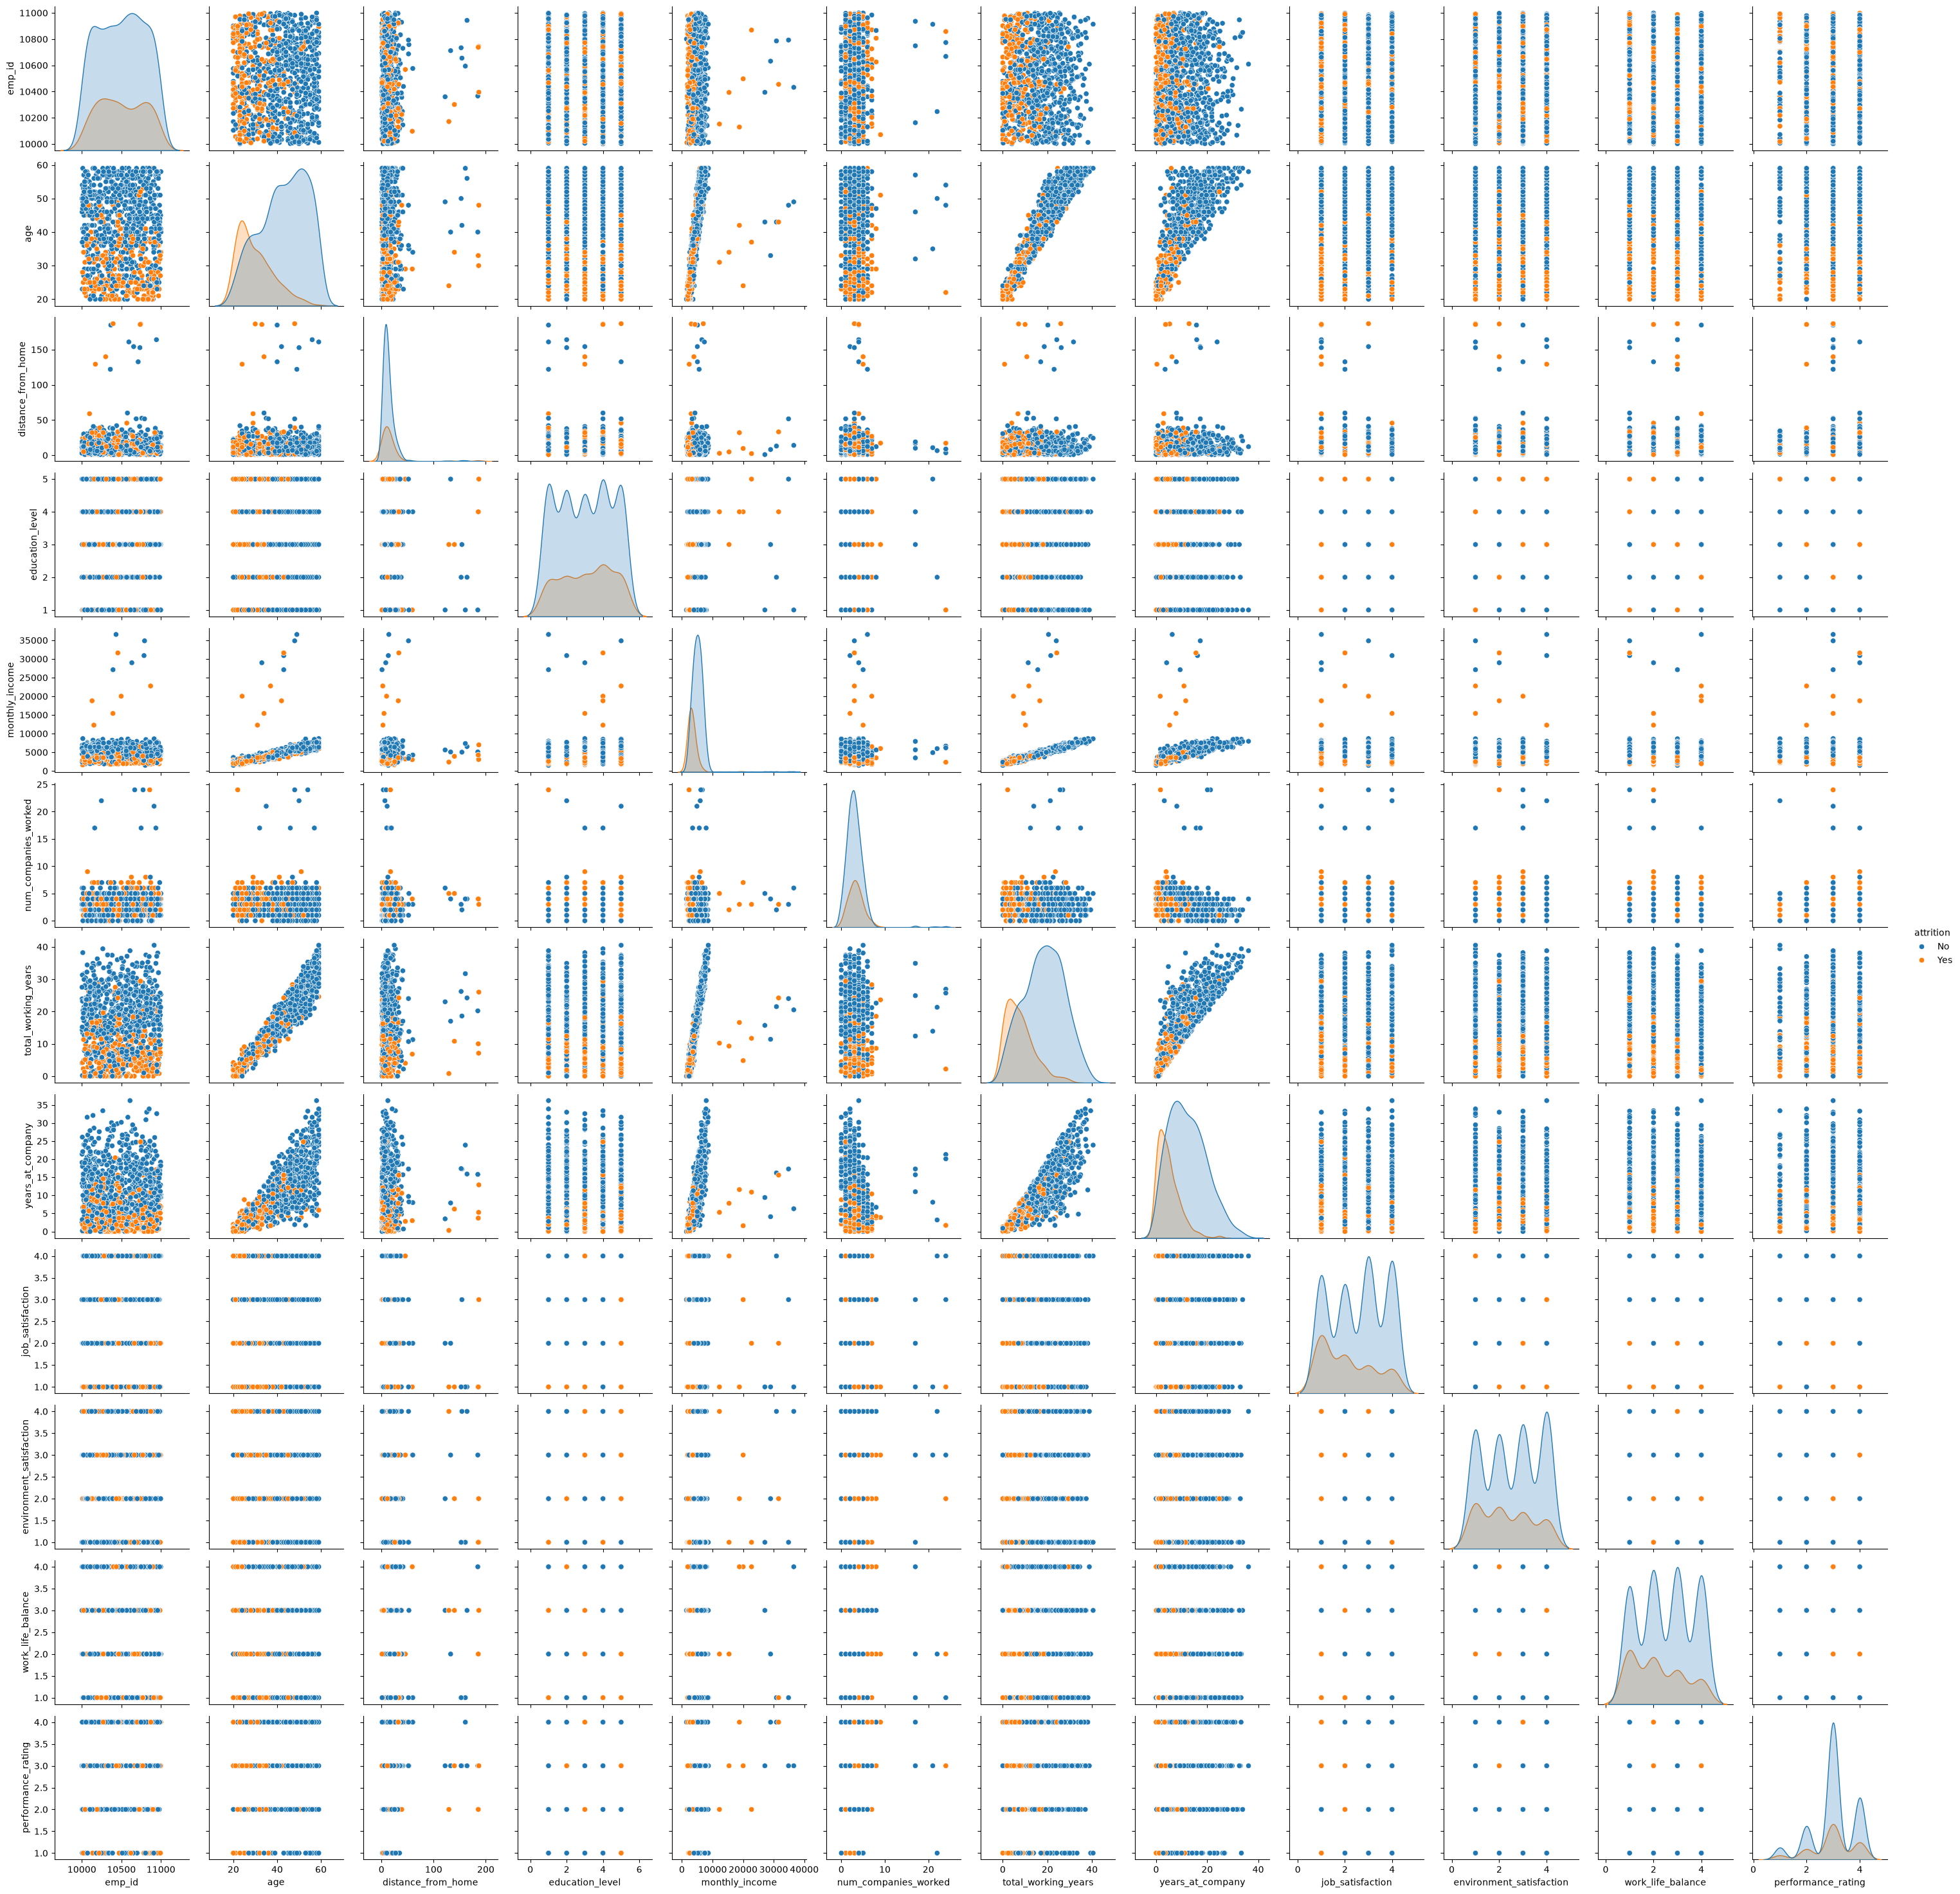

In [93]:
sns.pairplot(df, hue = "attrition")
plt.show()

## **3. 데이터 전처리하기**

In [156]:
import pandas as pd

# 전처리 과정에서 망가지면 여기서부터 다시 시작!
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/employee_attrition.csv")
df.head()

,emp_id,age,department,business_travel,distance_from_home,education_level,marital_status,monthly_income,num_companies_worked,overtime,total_working_years,years_at_company,job_satisfaction,environment_satisfaction,work_life_balance,performance_rating,attrition
0,10524,52,HR,Travel_Frequently,3.6,2,Single,5730.0,3,No,25.6,16.7,4.0,3,3.0,3,No
1,10603,49,R&D,Travel_Rarely,33.7,2,Divorced,5970.0,6,No,27.1,5.7,3.0,3,4.0,4,No
2,10527,56,Sales,Travel_Rarely,11.4,3,Married,7560.0,6,No,35.5,20.4,1.0,2,2.0,3,No
3,10032,29,Sales,Travel_Rarely,8.0,4,Married,4050.0,3,Yes,7.9,6.3,4.0,2,1.0,4,No
4,10617,29,R&D,Travel_Rarely,7.8,2,Divorced,2940.0,7,Yes,5.8,1.3,1.0,3,NaN,3,Yes


### **3-1. 중복 데이터와 불필요한 컬럼 처리하기**

**Q1. 중복된 행이 몇 개인지 확인하세요.**

In [157]:
# code here
df.duplicated().sum()

np.int64(20)

**Q2. 중복된 행을 제거하세요.**

In [158]:
# code here
df = df.drop_duplicates()

**Q3. emp_id 컬럼은 삭제해 주세요.**

In [159]:
# code here
df = df.drop("emp_id", axis = 1)

In [160]:
df

,age,department,business_travel,distance_from_home,education_level,marital_status,monthly_income,num_companies_worked,overtime,total_working_years,years_at_company,job_satisfaction,environment_satisfaction,work_life_balance,performance_rating,attrition
0,52,HR,Travel_Frequently,3.6,2,Single,5730.0,3,No,25.6,16.7,4.0,3,3.0,3,No
1,49,R&D,Travel_Rarely,33.7,2,Divorced,5970.0,6,No,27.1,5.7,3.0,3,4.0,4,No
2,56,Sales,Travel_Rarely,11.4,3,Married,7560.0,6,No,35.5,20.4,1.0,2,2.0,3,No
3,29,Sales,Travel_Rarely,8.0,4,Married,4050.0,3,Yes,7.9,6.3,4.0,2,1.0,4,No
4,29,R&D,Travel_Rarely,7.8,2,Divorced,2940.0,7,Yes,5.8,1.3,1.0,3,NaN,3,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1015,51,HR,Travel_Rarely,8.1,2,Single,5900.0,2,No,27.6,22.1,1.0,1,4.0,3,No
1016,31,R&D,Travel_Frequently,32.1,3,Single,3560.0,3,Yes,7.5,7.8,1.0,3,2.0,4,Yes
1017,58,Sales,Non-Travel,5.9,2,Single,7680.0,2,No,33.6,25.0,NaN,3,4.0,3,No
1018,24,Sales,Travel_Rarely,11.4,2,Married,1940.0,4,No,1.9,1.9,1.0,2,4.0,3,Yes


### **3-2. 데이터 분리하기**

**Q1.train과 test 데이터를 분리합니다.**
- target= "attrition"
- 학습데이터와 테스트 데이터의 비율은 7:3으로 합니다.
- 재현성을 위해 random_state = 101
- target 데이터의 비율을 최대한 유지하도록 stratify 옵션을 추가해 주세요.

In [161]:
# code here
y = df["attrition"]
X = df.drop("attrition",axis = 1)

In [162]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify= y, random_state=101)

### **3-3. 결측치 처리하기**

**Q1. train 데이터의 컬럼별 결측치 개수를 확인합니다.**

In [163]:
# code here
X_train.isnull().sum()

age                          0
department                   0
business_travel              0
distance_from_home           0
education_level              0
marital_status               0
monthly_income              38
num_companies_worked         0
overtime                     0
total_working_years          0
years_at_company             0
job_satisfaction            23
environment_satisfaction     0
work_life_balance           29
performance_rating           0
dtype: int64

In [164]:
X_test.isnull().sum()

age                          0
department                   0
business_travel              0
distance_from_home           0
education_level              0
marital_status               0
monthly_income              12
num_companies_worked         0
overtime                     0
total_working_years          0
years_at_company             0
job_satisfaction             7
environment_satisfaction     0
work_life_balance           11
performance_rating           0
dtype: int64

**Q2. 결측치를 다음과 같이 매꿔 줍니다.**
- monthly_income : 중앙값
- job_satisfaction, work_life_balance : 최빈값
- 반드시 train 데이터의 통계값을 test 데이터에도 동일하게 적용해야 합니다 (data leakage 방지).

In [165]:
# code here

monthly_fill = X_train["monthly_income"].median()
job_fill = X_train["job_satisfaction"].mode()[0]   # mode() 출력이 시리즈로 나옴
work_fill =X_train["work_life_balance"].mode()[0]

In [166]:
#위에서 찾은 값들로 X_train, X_test 둘다 채워주기
X_train["monthly_income"]= X_train["monthly_income"].fillna(monthly_fill)
X_train["job_satisfaction"]= X_train["job_satisfaction"].fillna(job_fill)
X_train["work_life_balance"]= X_train["work_life_balance"].fillna(work_fill)

In [167]:
X_train.isnull().sum()

age                         0
department                  0
business_travel             0
distance_from_home          0
education_level             0
marital_status              0
monthly_income              0
num_companies_worked        0
overtime                    0
total_working_years         0
years_at_company            0
job_satisfaction            0
environment_satisfaction    0
work_life_balance           0
performance_rating          0
dtype: int64

In [168]:
X_test["monthly_income"]= X_test["monthly_income"].fillna(monthly_fill)
X_test["job_satisfaction"]= X_test["job_satisfaction"].fillna(job_fill)
X_test["work_life_balance"]= X_test["work_life_balance"].fillna(work_fill)

In [169]:
X_test.isnull().sum()

age                         0
department                  0
business_travel             0
distance_from_home          0
education_level             0
marital_status              0
monthly_income              0
num_companies_worked        0
overtime                    0
total_working_years         0
years_at_company            0
job_satisfaction            0
environment_satisfaction    0
work_life_balance           0
performance_rating          0
dtype: int64

### **3-4. 이상치 처리하기**

**Q1. 각 컬럼에 대한 IQR 기준 이상치 개수를 확인하세요.**

In [170]:
# code here
def find_whisker(data, c):
    Q1 = data[c].quantile(0.25)
    Q3 = data[c].quantile(0.75)
    iqr = Q3 - Q1
    lower = Q1 - (1.5 * iqr)
    upper = Q3 + (1.5 * iqr)

    return (lower, upper)


In [171]:
# 숫자형 컬럼들의 이상치 확인
numeric_cols = X_train.select_dtypes(include = "number")


d = {} #지금 찾은 lower와 upper whisker를 저장
for c in numeric_cols:
    # 이 열에 대한 lower, upper whisker 찾기
    lower, upper = find_whisker(X_train, c)
    d[c] = (lower, upper)
    outliers = ((X_train[c] < lower) | (X_train[c] > upper)).sum()
    print(f"{c}: {outliers}")
    


age: 0
distance_from_home: 33
education_level: 0
monthly_income: 7
num_companies_worked: 9
total_working_years: 0
years_at_company: 6
job_satisfaction: 0
environment_satisfaction: 0
work_life_balance: 0
performance_rating: 319


In [172]:
X_train["performance_rating"].value_counts()

performance_rating
3    381
4    171
2    106
1     42
Name: count, dtype: int64

**Q2. performance_rating에 대한 각 항목의 개수와 boxplot을 그려 왜 이상치가 많이 보이는지 확인합니다.**

<Axes: xlabel='performance_rating'>

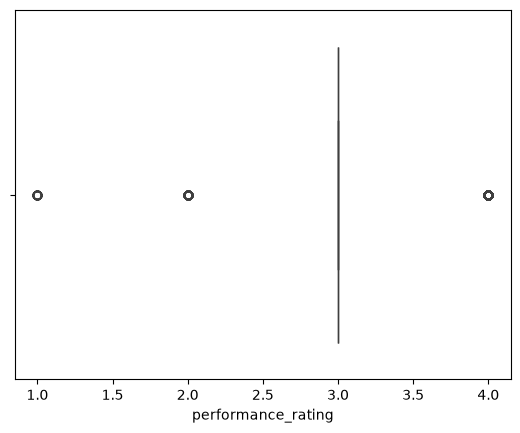

In [173]:
# code here

sns.boxplot(X_train, x = "performance_rating")

**Q2. 다음 컬럼들의 이상치를 clipping 합니다**
- monthly_income
- num_companies_worked
- years_at_company
- distance_from_home

In [ ]:
# code here
cols = ["monthly_income", "num_companies_worked", "years_at_company", "distance_from_home"]

for c in cols:  
    # train, test cliping 하기
    lower, upper = d[c]
    X_train[c] = X_train[c].clip(lower, upper)
    X_test[c] = X_test[c].clip(lower, upper)


### **3-5. Feature Encoding**

**Q1. 이진 범주형 컬럼 overtime을 Label Encoding 하세요.**

In [ ]:
# code here
# from sklearn.preprocessing import LabelEncoder

# le = LabelEncoder()

# X_train["overtime"] = le.fit_transform(X_train["overtime"])
# X_test["overtime"] = le.transform(X_test["overtime"])
# 2.mapping
X_train["overtime"] = X_train["overtime"].map({"Yes" : 1, "No" : 0})
X_test["overtime"] = X_test["overtime"].map({"Yes" : 1, "No" : 0})

X_train

,age,department,business_travel,distance_from_home,education_level,marital_status,monthly_income,num_companies_worked,overtime,total_working_years,years_at_company,job_satisfaction,environment_satisfaction,work_life_balance,performance_rating
951,43,R&D,Travel_Frequently,7.10,4,Married,4440.0,0,0,14.1,12.4,3.0,3,1.0,4
989,38,HR,Travel_Frequently,32.45,5,Married,3580.0,1,1,13.2,9.1,1.0,1,4.0,3
710,31,R&D,Travel_Rarely,32.45,3,Single,3150.0,4,0,5.8,4.7,1.0,1,2.0,3
440,54,R&D,Travel_Frequently,6.30,5,Single,7300.0,2,1,31.3,19.4,2.0,4,3.0,4
749,45,Sales,Non-Travel,2.40,5,Married,4740.0,1,0,17.9,13.4,2.0,2,2.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
443,53,HR,Travel_Rarely,29.20,4,Divorced,5520.0,2,1,19.4,15.4,4.0,1,4.0,2
979,49,Sales,Travel_Rarely,6.30,5,Married,6650.0,4,0,23.7,10.9,4.0,2,3.0,3
290,55,HR,Travel_Rarely,3.00,2,Married,6420.0,2,1,22.7,15.9,2.0,1,1.0,2
23,41,Sales,Non-Travel,6.80,4,Single,3790.0,3,0,11.2,8.6,1.0,1,2.0,3


**Q2. 다범주 컬럼 department, business_travel, marital_status를 One-Hot Encoding 하세요.**

여러 컬럼을 한번에 원-핫 인코딩하려면, 다음 옵션이 필요할 수 있습니다.

```
ohe = OneHotEncoder(drop="first", sparse_output=False)
```

In [176]:
# code here
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, drop='first')

In [177]:
ohe_cols = ["department", "business_travel", "marital_status"]
X_train_encoded = ohe.fit_transform(X_train[ohe_cols])
X_train_encoded = pd.DataFrame(X_train_encoded, columns=ohe.get_feature_names_out(), index=X_train.index)

X_train_encoded = pd.concat([X_train.drop(ohe_cols, axis = 1), X_train_encoded], axis = 1)

In [ ]:
ohe_cols = ["department", "business_travel", "marital_status"]
X_test_encoded = ohe.transform(X_test[ohe_cols])
X_test_encoded = pd.DataFrame(X_test_encoded, columns=ohe.get_feature_names_out(), index=X_test.index)

X_test_encoded = pd.concat([X_test.drop(ohe_cols, axis = 1), X_test_encoded], axis = 1)


,age,distance_from_home,education_level,monthly_income,num_companies_worked,overtime,total_working_years,years_at_company,job_satisfaction,environment_satisfaction,work_life_balance,performance_rating,department_R&D,department_Sales,business_travel_Travel_Frequently,business_travel_Travel_Rarely,marital_status_Married,marital_status_Single
329,35,3.1,5,3430.0,6,0,8.0,3.3,4.0,1,4.0,3,0.0,1.0,0.0,1.0,0.0,0.0
743,47,6.3,5,5710.0,3,1,22.1,8.2,3.0,2,3.0,3,1.0,0.0,1.0,0.0,1.0,0.0
271,56,11.9,1,6600.0,2,1,29.7,24.0,4.0,1,2.0,3,1.0,0.0,0.0,0.0,0.0,1.0
769,22,4.4,3,4495.0,4,0,1.6,1.4,3.0,4,2.0,4,0.0,1.0,0.0,1.0,0.0,1.0
540,51,32.4,3,6070.0,2,0,24.3,16.1,2.0,2,2.0,4,0.0,1.0,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
365,55,3.7,3,6640.0,2,0,28.4,21.8,3.0,1,1.0,3,0.0,1.0,1.0,0.0,1.0,0.0
504,37,11.2,5,4220.0,3,1,15.3,11.7,3.0,2,4.0,3,0.0,1.0,0.0,0.0,0.0,1.0
900,35,7.2,1,4160.0,4,0,16.5,8.3,1.0,2,2.0,2,0.0,1.0,1.0,0.0,0.0,1.0
990,44,11.5,1,4590.0,4,0,17.3,8.7,3.0,1,1.0,4,1.0,0.0,0.0,0.0,0.0,1.0


## **4. 모델링**

### **4-1. 단일 트리**

**Q1.DecisionTreeClassifier (기본)을 학습시키고 test 정확도를 확인하세요.**

- 하이퍼파라미터 튜닝 (Grid/Randomized Search) 없이 default Decision Tree를 활용해봅니다.

In [180]:
# code here

from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier()
tree_model.fit(X_train_encoded, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

**Q2. 정확도, 분류 리포트, 혼동 행렬로 성능을 확인합니다.**

In [185]:
# code here
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_tree = tree_model.predict(X_test_encoded)
print(f"accuracy: {accuracy_score(y_test, y_pred_tree) * 100}%")

accuracy: 73.33333333333333%


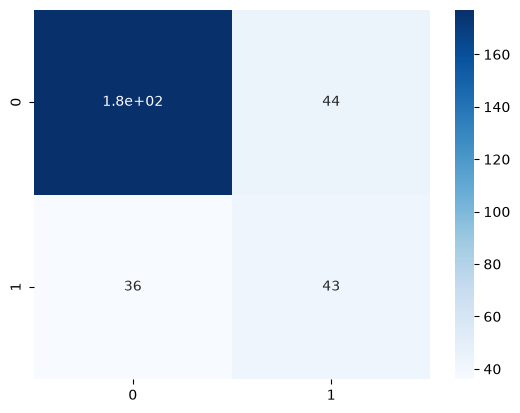

In [184]:
sns.heatmap(confusion_matrix(y_test, y_pred_tree), cmap = "Blues", annot=True)
plt.show()

In [183]:
print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

          No       0.83      0.80      0.82       221
         Yes       0.49      0.54      0.52        79

    accuracy                           0.73       300
   macro avg       0.66      0.67      0.67       300
weighted avg       0.74      0.73      0.74       300



### **4-1.5 Voting model**

In [186]:
# 다른 모델들이 같은 데이터로 학습하는 ensemble
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# 이 voting 어벤져스에 포함될 모델들을 먼저 지정을 해줘야 함
lr_model = LogisticRegression()
knn_model = KNeighborsClassifier(n_neighbors=5)
tree_model2 = DecisionTreeClassifier()

voting_model = VotingClassifier(
    estimators=[
        ("logistic regression model", lr_model),
        ("knn model", knn_model),
        ("tree model", tree_model2)
    ],
    # 투표 방식
    # 1. hard voting: 라벨의 결과를 가지고 다수결 투표
    # 2. soft voting: 각 모델들의  각 라벨에 대한 확률을 가지고 평균을 내서 결정
    voting = 'hard'
)

In [187]:
voting_model.fit(X_train_encoded, y_train)

c:\Users\user\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('logistic regression model', ...), ('knn model', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](2,)","['No','Yes']"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[LogisticRegression(), KNeighborsClassifier(), DecisionTreeClassifier()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['age','distance_from_home','education_level',..., 'business_travel_Travel_Rarely','marital_status_Married', 'marital_status_Single']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [188]:
y_pred_vote = voting_model.predict(X_test_encoded)

In [189]:
print(f"accuracy : {accuracy_score(y_test, y_pred_vote)}")

accuracy : 0.7833333333333333


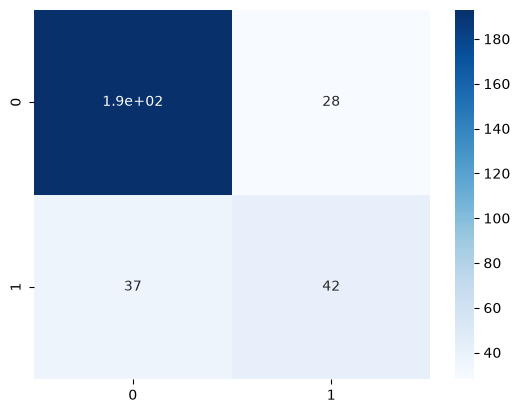

In [192]:
sns.heatmap(confusion_matrix(y_test, y_pred_vote), annot=True, cmap="Blues")
plt.show()

In [191]:
print(classification_report(y_test, y_pred_vote))

              precision    recall  f1-score   support

          No       0.84      0.87      0.86       221
         Yes       0.60      0.53      0.56        79

    accuracy                           0.78       300
   macro avg       0.72      0.70      0.71       300
weighted avg       0.78      0.78      0.78       300



### **4-2. 랜덤 포레스트**

**Q1.RandomForestClassifier (기본)을 학습시키고 평가를 해주세요.**

In [195]:
# code here
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    random_state=101
)

model.fit(X_train_encoded, y_train)
y_pred = model.predict(X_test_encoded)

In [196]:
print(f"accuracy: {accuracy_score(y_test, y_pred)}")

accuracy: 0.7933333333333333


<Axes: >

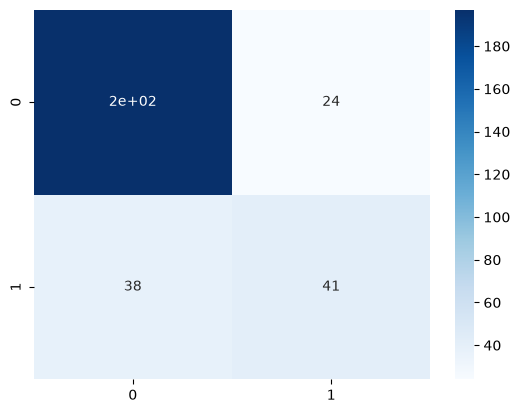

In [197]:
sns.heatmap(confusion_matrix(y_test, y_pred), cmap = "Blues", annot=True)

In [198]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.84      0.89      0.86       221
         Yes       0.63      0.52      0.57        79

    accuracy                           0.79       300
   macro avg       0.73      0.71      0.72       300
weighted avg       0.78      0.79      0.79       300



### **4-3. 하이퍼파라미터 튜닝 (GridSearchCV)**

**Q1. Grid Search를 이용해 hyperparameter tuning을 해봅시다.**

Sample space는 다음과 같이 활용합니다.
- cv = skf, scoring = 'accuracy'
- n_estimators: [100, 200, 300]
- max_depth: [3, 5, 7, 10]
- min_samples_split: [2, 5, 10]
- min_samples_leaf: [1, 2, 4]

CV에서 Stratified K Fold를 활용해봅니다.
```
from sklearn.model_selection import GridSearchCV, StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=101)

grid_search = GridSearchCV(
    RandomForestClassifier(),
    param_grid=param_grid,
    cv=skf,
    scoring="accuracy",
)
```

**GridSearch에서 학습 시간이 조금 걸릴 수 있습니다.**

In [ ]:
# code here
# search space 만들기
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "n_estimators" : [100, 200, 300],
    "max_depth" : [3, 5, 7, 10],
    "min_samples_split" : [2, 5, 10],
    "min_samples_leaf" : [1, 2, 4]
    # 그 외의 max_feature (feature randomness) 는 default로 sqrt로 잡혀있고,
    # bootstrap = True로 잡혀있음
}

In [266]:
grid_search = GridSearchCV(
    RandomForestClassifier(),
    param_grid=param_grid,
    cv = 20,
    scoring = "accuracy",  # 정확도가 제일 높은걸 제일 좋은걸로 판단
    verbose = 2,
    n_jobs=-1
)

In [267]:
# 학습 시작
grid_search.fit(X_train_encoded, y_train)

Fitting 20 folds for each of 108 candidates, totalling 2160 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",20
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_ex

### **4-4. 예측하기**

**Q1. 최적의 하이퍼파라미터를 적용한 모델로 test 데이터에 대한 예측값을 구하세요.**

In [268]:
model = grid_search.best_estimator_

In [206]:
# code here
y_pred = model.predict(X_test_encoded)
print(f"accuracy: {accuracy_score(y_test, y_pred)}")

accuracy: 0.7866666666666666


### **4-5. 모델 평가하기**

**Q1. accuracy, classification report, confusion matrix로 모델 성능을 평가하세요.**

In [210]:
# code here
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.87      0.86       221
         Yes       0.60      0.56      0.58        79

    accuracy                           0.79       300
   macro avg       0.72      0.71      0.72       300
weighted avg       0.78      0.79      0.78       300



### **4-6. Feature Importance 확인하기**

**Q. 모델의 feature_importances_를 막대그래프로 시각화하여 어떤 특징이 이직 예측에 가장 중요한지 확인하세요.**

In [208]:
# code here
feature_importances = pd.Series(model.feature_importances_, index = X_train_encoded.columns)
feature_importances = feature_importances.sort_values(ascending=False)

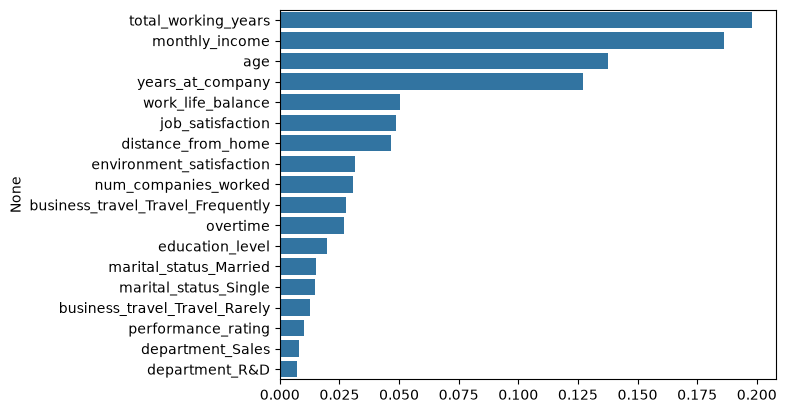

In [209]:
sns.barplot(x = feature_importances.values, y = feature_importances.index)
plt.show()

## **5. 채점하기**

데이터 전처리 방법과 학습된 모델을 활용하여 미공개 데이터에 대해 mushroom_id에 일치하는 예측 결과를 DataFrame의 "attrition" 컬럼에 기입하고 .csv파일로 저장하여 제출합니다.

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/employee_attrition_submission.csv

In [242]:
submission = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/employee_attrition_submission.csv")
submission.head()

,emp_id,age,department,business_travel,distance_from_home,education_level,marital_status,monthly_income,num_companies_worked,overtime,total_working_years,years_at_company,job_satisfaction,environment_satisfaction,work_life_balance,performance_rating
0,90001,58,HR,Travel_Rarely,2.6,1,Single,7450.0,1,No,30.3,28.3,3,1,4,2
1,90002,45,HR,Travel_Rarely,4.2,5,Single,5400.0,4,No,24.8,21.1,4,3,4,3
2,90003,51,Sales,Travel_Rarely,5.9,4,Single,6720.0,4,No,26.9,14.4,1,1,3,2
3,90004,58,HR,Travel_Rarely,7.5,5,Married,7040.0,4,No,30.4,16.1,2,4,1,3
4,90005,56,Sales,Travel_Rarely,5.5,1,Married,5890.0,1,No,24.4,21.1,3,3,4,3


In [243]:
# code here
ids = submission["emp_id"]
submission = submission.drop("emp_id", axis = 1)

In [244]:
ids

0     90001
1     90002
2     90003
3     90004
4     90005
      ...  
95    90096
96    90097
97    90098
98    90099
99    90100
Name: emp_id, Length: 100, dtype: int64

In [245]:
submission["overtime"] = submission["overtime"].map({"Yes" : 1, "No" : 0})
submission

,age,department,business_travel,distance_from_home,education_level,marital_status,monthly_income,num_companies_worked,overtime,total_working_years,years_at_company,job_satisfaction,environment_satisfaction,work_life_balance,performance_rating
0,58,HR,Travel_Rarely,2.6,1,Single,7450.0,1,0,30.3,28.3,3,1,4,2
1,45,HR,Travel_Rarely,4.2,5,Single,5400.0,4,0,24.8,21.1,4,3,4,3
2,51,Sales,Travel_Rarely,5.9,4,Single,6720.0,4,0,26.9,14.4,1,1,3,2
3,58,HR,Travel_Rarely,7.5,5,Married,7040.0,4,0,30.4,16.1,2,4,1,3
4,56,Sales,Travel_Rarely,5.5,1,Married,5890.0,1,0,24.4,21.1,3,3,4,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,30,HR,Travel_Rarely,29.2,1,Married,3200.0,3,0,7.6,4.8,4,3,2,3
96,36,R&D,Travel_Rarely,5.9,1,Single,2740.0,3,0,8.6,5.0,3,4,4,4
97,23,R&D,Travel_Rarely,19.7,1,Divorced,2660.0,2,0,2.1,1.2,4,3,2,2
98,40,Sales,Non-Travel,17.2,1,Single,3890.0,3,1,14.8,10.8,4,3,2,4


In [246]:
ohe_cols_sb = ["department", "business_travel", "marital_status"]

submission_encoded = ohe.transform(submission[ohe_cols_sb])

In [247]:
submission_encoded = pd.DataFrame(submission_encoded, columns=ohe.get_feature_names_out(), index=submission.index)

In [248]:
submission_encoded = pd.concat([submission.drop(ohe_cols_sb, axis = 1),  submission_encoded], axis = 1)

In [249]:
submission_encoded

,age,distance_from_home,education_level,monthly_income,num_companies_worked,overtime,total_working_years,years_at_company,job_satisfaction,environment_satisfaction,work_life_balance,performance_rating,department_R&D,department_Sales,business_travel_Travel_Frequently,business_travel_Travel_Rarely,marital_status_Married,marital_status_Single
0,58,2.6,1,7450.0,1,0,30.3,28.3,3,1,4,2,0.0,0.0,0.0,1.0,0.0,1.0
1,45,4.2,5,5400.0,4,0,24.8,21.1,4,3,4,3,0.0,0.0,0.0,1.0,0.0,1.0
2,51,5.9,4,6720.0,4,0,26.9,14.4,1,1,3,2,0.0,1.0,0.0,1.0,0.0,1.0
3,58,7.5,5,7040.0,4,0,30.4,16.1,2,4,1,3,0.0,0.0,0.0,1.0,1.0,0.0
4,56,5.5,1,5890.0,1,0,24.4,21.1,3,3,4,3,0.0,1.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,30,29.2,1,3200.0,3,0,7.6,4.8,4,3,2,3,0.0,0.0,0.0,1.0,1.0,0.0
96,36,5.9,1,2740.0,3,0,8.6,5.0,3,4,4,4,1.0,0.0,0.0,1.0,0.0,1.0
97,23,19.7,1,2660.0,2,0,2.1,1.2,4,3,2,2,1.0,0.0,0.0,1.0,0.0,0.0
98,40,17.2,1,3890.0,3,1,14.8,10.8,4,3,2,4,0.0,1.0,0.0,0.0,0.0,1.0


In [269]:
y_pred_sb = model.predict(submission_encoded)

In [270]:
y_pred_sb = pd.DataFrame(y_pred_sb, columns=["attrition"])

In [271]:
pd.concat([ids, y_pred_sb], axis = 1).to_csv("attrition.csv", index=False)